In [2]:

import pandas as pd

df = pd.read_parquet('/content/test-00000-of-00001.parquet')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())


Dataset loaded successfully!
Shape: (115, 5)

Column names:
['image_id', 'image', 'width', 'height', 'objects']

First 5 rows:


,image_id,image,width,height,objects
0,18111,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,880,1024,"{'bbox_id': [2583, 2584, 2585, 2586, 2587, 258..."
1,19436,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,681,1024,"{'bbox_id': [4010, 4011, 4012, 4013, 4014, 401..."
2,12153,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,682,1024,"{'bbox_id': [8053, 8054, 8055, 8056, 8057, 805..."
3,11931,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,682,1024,"{'bbox_id': [7844, 7845, 7846, 7847, 7848, 784..."
4,9390,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...,1024,683,"{'bbox_id': [6614, 6615, 6616, 6617, 6618, 661..."


In [3]:
print(df['objects'].iloc[0])


{'bbox_id': array([2583, 2584, 2585, 2586, 2587, 2588, 2589, 2590]), 'category': array([23, 23,  9, 28, 31, 31, 19, 34]), 'bbox': array([array([445., 837., 498., 944.]), array([475., 889., 531., 978.]),
       array([355., 245., 594., 667.]), array([379., 245., 502., 301.]),
       array([508., 273., 594., 541.]), array([355., 295., 389., 573.]),
       array([366., 397., 518., 449.]), array([421., 397., 441., 428.])],
      dtype=object), 'area': array([ 1475,  1703, 79872,  2153, 10313,  5710,  3712,   358])}


In [4]:
print(df['objects'].iloc[0]['category'])

[23 23  9 28 31 31 19 34]


In [5]:
from collections import Counter

categories = Counter()

for objects in df['objects']:
    categories.update(objects['category'])

print(categories)

Counter({np.int64(23): 143, np.int64(31): 130, np.int64(33): 97, np.int64(32): 54, np.int64(1): 53, np.int64(10): 52, np.int64(6): 25, np.int64(35): 24, np.int64(24): 21, np.int64(28): 19, np.int64(8): 18, np.int64(4): 17, np.int64(19): 16, np.int64(15): 15, np.int64(21): 14, np.int64(13): 11, np.int64(29): 10, np.int64(7): 10, np.int64(0): 9, np.int64(18): 9, np.int64(34): 8, np.int64(37): 8, np.int64(36): 8, np.int64(9): 7, np.int64(14): 7, np.int64(42): 6, np.int64(43): 5, np.int64(22): 5, np.int64(27): 4, np.int64(25): 4, np.int64(5): 4, np.int64(44): 3, np.int64(40): 3, np.int64(11): 2, np.int64(30): 2, np.int64(41): 1, np.int64(3): 1, np.int64(26): 1, np.int64(12): 1, np.int64(38): 1})


In [6]:
category_names = {
    0: "Shirt/Blouse",
    1: "Top/T-shirt/Sweatshirt",
    2: "Sweater",
    3: "Cardigan",
    4: "Jacket",
    5: "Vest",
    6: "Pants",
    7: "Shorts",
    8: "Skirt",
    9: "Coat",
    10: "Dress",
    11: "Jumpsuit",
    19: "Belt",
    23: "Shoe",
    24: "Bag/Wallet",
    28: "Collar",
    31: "Sleeve",
    32: "Pocket",
    33: "Neckline",
    34: "Buckle",
    35: "Zipper"
}

for category_id, count in categories.most_common():
    print(category_names.get(int(category_id), f"Other ({category_id})"), count)

Shoe 143
Sleeve 130
Neckline 97
Pocket 54
Top/T-shirt/Sweatshirt 53
Dress 52
Pants 25
Zipper 24
Bag/Wallet 21
Collar 19
Skirt 18
Jacket 17
Belt 16
Other (15) 15
Other (21) 14
Other (13) 11
Other (29) 10
Shorts 10
Shirt/Blouse 9
Other (18) 9
Buckle 8
Other (37) 8
Other (36) 8
Coat 7
Other (14) 7
Other (42) 6
Other (43) 5
Other (22) 5
Other (27) 4
Other (25) 4
Vest 4
Other (44) 3
Other (40) 3
Jumpsuit 2
Other (30) 2
Other (41) 1
Cardigan 1
Other (26) 1
Other (12) 1
Other (38) 1


In [7]:

import pandas as pd

category_counts = pd.Series({
    int(category): count
    for category, count in categories.items()
})

total_objects = category_counts.sum()

popularity = (category_counts / total_objects) * 100

result = pd.DataFrame({
    'Category ID': category_counts.index,
    'Count': category_counts.values,
    'Popularity (%)': popularity.values
})

result = result.sort_values(
    by='Popularity (%)',
    ascending=False
)

print(result)


    Category ID  Count  Popularity (%)
0            23    143       17.270531
3            31    130       15.700483
10           33     97       11.714976
12           32     54        6.521739
11            1     53        6.400966
18           10     52        6.280193
13            6     25        3.019324
8            35     24        2.898551
21           24     21        2.536232
2            28     19        2.294686
14            8     18        2.173913
15            4     17        2.053140
4            19     16        1.932367
6            15     15        1.811594
17           21     14        1.690821
7            13     11        1.328502
23           29     10        1.207729
25            7     10        1.207729
24           18      9        1.086957
9             0      9        1.086957
19           37      8        0.966184
5            34      8        0.966184
31           36      8        0.966184
1             9      7        0.845411
22           14      7   

In [8]:

!pip install transformers torch


In [9]:
import torch
from transformers import CLIPProcessor, CLIPModel

model_name = "openai/clip-vit-base-patch32"

processor = CLIPProcessor.from_pretrained(model_name)
model = CLIPModel.from_pretrained(model_name)

device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)

print("CLIP loaded successfully!")
print("Device:", device)

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP loaded successfully!
Device: cpu


In [10]:

from PIL import Image
from io import BytesIO

# Get the first image
img_data = df.iloc[0]["image"]

# Convert the dataset image into a PIL image
if isinstance(img_data, dict):
    image = Image.open(BytesIO(img_data["bytes"])).convert("RGB")
else:
    image = img_data.convert("RGB")

# Possible fashion descriptions
labels = [
    "A floral dress",
    "A striped shirt",
    "A checked jacket",
    "A plain skirt"
]

# Give image and descriptions to CLIP
inputs = processor(
    text=labels,
    images=image,
    return_tensors="pt",
    padding=True
).to(device)

# Predict similarity scores
with torch.no_grad():
    outputs = model(**inputs)

scores = outputs.logits_per_image.softmax(dim=1)[0]

# Display results
for label, score in zip(labels, scores):
    print(label, ":", round(score.item() * 100, 2), "%")


model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

A floral dress : 38.54 %
A striped shirt : 0.11 %
A checked jacket : 41.63 %
A plain skirt : 19.73 %


In [11]:

clothing_types = [
    "A photograph of a dress",
    "A photograph of a shirt",
    "A photograph of a jacket",
    "A photograph of a skirt",
    "A photograph of trousers"
]

patterns = [
    "Floral patterned clothing",
    "Striped clothing",
    "Checked clothing",
    "Plain solid-colour clothing",
    "Polka dot clothing"
]

def predict(labels):
    inputs = processor(
        text=labels,
        images=image,
        return_tensors="pt",
        padding=True
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs)

    scores = outputs.logits_per_image.softmax(dim=1)[0]

    for label, score in zip(labels, scores):
        print(label, ":", round(score.item() * 100, 2), "%")

print("CLOTHING TYPE")
predict(clothing_types)

print("\nCLOTHING PATTERN")
predict(patterns)


CLOTHING TYPE
A photograph of a dress : 29.72 %
A photograph of a shirt : 0.35 %
A photograph of a jacket : 66.92 %
A photograph of a skirt : 2.8 %
A photograph of trousers : 0.21 %

CLOTHING PATTERN
Floral patterned clothing : 16.07 %
Striped clothing : 0.82 %
Checked clothing : 2.95 %
Plain solid-colour clothing : 72.04 %
Polka dot clothing : 8.12 %


In [13]:

type_labels = [
    "A photograph of a dress",
    "A photograph of a shirt",
    "A photograph of a jacket",
    "A photograph of a skirt",
    "A photograph of trousers"
]

pattern_labels = [
    "Floral patterned clothing",
    "Striped clothing",
    "Checked clothing",
    "Plain solid-colour clothing",
    "Polka dot clothing"
]

def get_prediction(img, labels):
    inputs = processor(
        text=labels,
        images=img,
        return_tensors="pt",
        padding=True
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs)

    scores = outputs.logits_per_image.softmax(dim=1)[0]
    return labels[torch.argmax(scores).item()]

results = []

for i, item in enumerate(df['image']):
    if isinstance(item, dict):
        img = Image.open(BytesIO(item['bytes'])).convert("RGB")
    else:
        img = item.convert("RGB")

    clothing = get_prediction(img, type_labels)
    pattern = get_prediction(img, pattern_labels)

    results.append({
        "image_id": df.iloc[i]["image_id"],
        "clothing_type": clothing,
        "pattern": pattern
    })

results_df = pd.DataFrame(results)

display(results_df)

print("All images processed!")


,image_id,clothing_type,pattern
0,18111,A photograph of a jacket,Plain solid-colour clothing
1,19436,A photograph of trousers,Plain solid-colour clothing
2,12153,A photograph of a jacket,Polka dot clothing
3,11931,A photograph of a dress,Floral patterned clothing
4,9390,A photograph of trousers,Plain solid-colour clothing
...,...,...,...
110,12548,A photograph of trousers,Polka dot clothing
111,15812,A photograph of a dress,Plain solid-colour clothing
112,18696,A photograph of a dress,Plain solid-colour clothing
113,17090,A photograph of a jacket,Checked clothing


All images processed!


In [14]:
print("CLOTHING TYPE DISTRIBUTION")
print(results_df['clothing_type'].value_counts())

print("\nPATTERN DISTRIBUTION")
print(results_df['pattern'].value_counts())

CLOTHING TYPE DISTRIBUTION
clothing_type
A photograph of a dress     42
A photograph of a skirt     31
A photograph of a jacket    19
A photograph of trousers    14
A photograph of a shirt      9
Name: count, dtype: int64

PATTERN DISTRIBUTION
pattern
Plain solid-colour clothing    62
Floral patterned clothing      29
Polka dot clothing             17
Striped clothing                5
Checked clothing                2
Name: count, dtype: int64


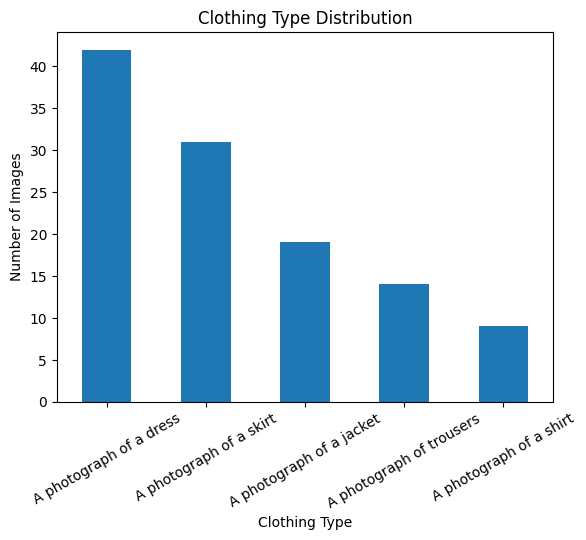

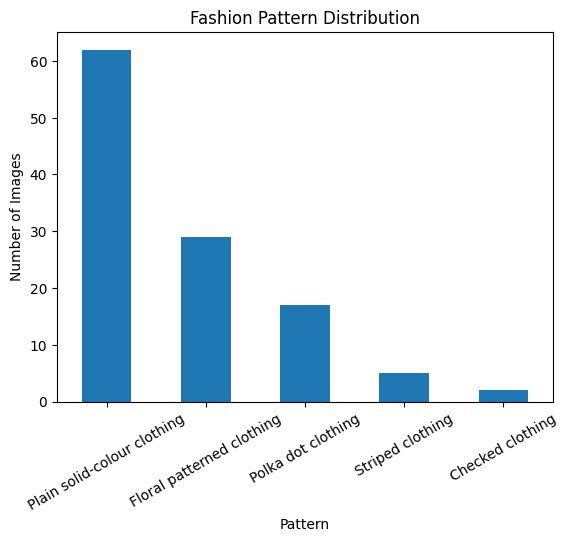

In [15]:

import matplotlib.pyplot as plt

# Clothing type graph
results_df['clothing_type'].value_counts().plot(
    kind='bar',
    title='Clothing Type Distribution'
)

plt.xlabel('Clothing Type')
plt.ylabel('Number of Images')
plt.xticks(rotation=30)
plt.show()


# Pattern graph
results_df['pattern'].value_counts().plot(
    kind='bar',
    title='Fashion Pattern Distribution'
)

plt.xlabel('Pattern')
plt.ylabel('Number of Images')
plt.xticks(rotation=30)
plt.show()


In [16]:
import os

print(os.listdir('/content'))

['.config', 'test-00000-of-00001.parquet', 'json_for_validation.zip', 'validation.zip', 'sample_data']


In [18]:
import os
import zipfile

for filename in ['validation.zip', 'json_for_validation.zip']:
    path = '/content/' + filename

    print("\nFile:", filename)
    print("Size:", os.path.getsize(path), "bytes")
    print("Valid ZIP:", zipfile.is_zipfile(path))

    with open(path, 'rb') as f:
        print("First bytes:", f.read(100))


File: validation.zip
Size: 742391808 bytes
Valid ZIP: False
First bytes: b"PK\x03\x04\n\x00\x00\x00\x00\x00\xb6\xa0\xb6N\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x0b\x00\x1c\x00validation/UT\t\x00\x03\x17;\xe5\\'\xc7\xec\\ux\x0b\x00\x01\x04\xe8\x03\x00\x00\x04\xe8\x03\x00\x00PK\x03\x04\n\x00\x00\x00\x00\x00\xd5\xa6\xb6N\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x11\x00\x1c\x00v"

File: json_for_validation.zip
Size: 14895000 bytes
Valid ZIP: True
First bytes: b'PK\x03\x04\n\x00\x00\x00\x00\x00D\x8d\xb8N\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x14\x00\x1c\x00json_for_validation/UT\t\x00\x03p\xbc\xe7\\\x10~\xfe\\ux\x0b\x00\x01\x04\xe8\x03\x00\x00\x04\xe8\x03\x00\x00PK\x03\x04\x14\x00\t\x00\x08\x00\xdbQ\xb8N1\xf2\x9a\x7f+I\x02\x00'


In [19]:
!unzip -t /content/validation.zip | tail -20

  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of /content/validation.zip or
        /content/validation.zip.zip, and cannot find /content/validation.zip.ZIP, period.
Archive:  /content/validation.zip
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of /content/validation.zip or
        /content/validation.zip.zip, and cannot find /content/validation.zip.ZIP, period.


In [21]:
import zipfile
import os

with zipfile.ZipFile('/content/json_for_validation.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/deepfashion_annotations')

print("Annotations extracted successfully!")

RuntimeError: File <ZipInfo filename='json_for_validation/val_query.json' compress_type=deflate filemode='-rw-rw-r--' file_size=1149275 compress_size=149803> is encrypted, password required for extraction

In [22]:
import zipfile

try:
    with zipfile.ZipFile('/content/json_for_validation.zip', 'r') as zip_ref:
        print("ZIP opened successfully!")
        print("Number of files:", len(zip_ref.namelist()))
        zip_ref.extractall('/content/deepfashion_annotations')
        print("Extraction successful!")

except Exception as e:
    print("Error type:", type(e).__name__)
    print("Error details:", str(e))

ZIP opened successfully!
Number of files: 8
Error type: RuntimeError
Error details: File <ZipInfo filename='json_for_validation/val_query.json' compress_type=deflate filemode='-rw-rw-r--' file_size=1149275 compress_size=149803> is encrypted, password required for extraction


In [23]:
print("Dataset:", df.shape)
print("CLIP results:", results_df.shape)

display(results_df.head())

Dataset: (115, 5)
CLIP results: (115, 3)


,image_id,clothing_type,pattern
0,18111,A photograph of a jacket,Plain solid-colour clothing
1,19436,A photograph of trousers,Plain solid-colour clothing
2,12153,A photograph of a jacket,Polka dot clothing
3,11931,A photograph of a dress,Floral patterned clothing
4,9390,A photograph of trousers,Plain solid-colour clothing


In [24]:
results_df.to_csv("fashionpedia_clip_results.csv", index=False)

print("CSV saved successfully!")

CSV saved successfully!


In [25]:
from google.colab import files
files.download("fashionpedia_clip_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
from PIL import Image
from io import BytesIO
import pandas as pd
import colorsys

def get_dominant_color(img):
    # Resize image to make processing faster
    img = img.resize((100, 100))

    # Reduce image to its 5 most common colours
    img = img.quantize(colors=5)

    # Find the most common colour
    colors = img.getcolors()

    dominant_index = max(colors)[1]
    palette = img.getpalette()

    r = palette[dominant_index * 3]
    g = palette[dominant_index * 3 + 1]
    b = palette[dominant_index * 3 + 2]

    return r, g, b

In [27]:
def get_color_name(rgb):
    r, g, b = [x / 255 for x in rgb]

    h, s, v = colorsys.rgb_to_hsv(r, g, b)

    if v < 0.2:
        return "Black"
    elif s < 0.15 and v > 0.85:
        return "White"
    elif s < 0.15:
        return "Grey"
    elif h < 0.04 or h >= 0.95:
        return "Red"
    elif h < 0.10:
        return "Orange"
    elif h < 0.17:
        return "Yellow"
    elif h < 0.42:
        return "Green"
    elif h < 0.55:
        return "Cyan"
    elif h < 0.75:
        return "Blue"
    elif h < 0.90:
        return "Purple"
    else:
        return "Pink"

In [28]:
dominant_colors = []

for item in df['image']:

    if isinstance(item, dict):
        img = Image.open(BytesIO(item['bytes'])).convert("RGB")
    else:
        img = item.convert("RGB")

    rgb = get_dominant_color(img)
    color_name = get_color_name(rgb)

    dominant_colors.append(color_name)

results_df['colour'] = dominant_colors

print("Colour detection completed!")
display(results_df.head(10))

Colour detection completed!


,image_id,clothing_type,pattern,colour
0,18111,A photograph of a jacket,Plain solid-colour clothing,Black
1,19436,A photograph of trousers,Plain solid-colour clothing,Black
2,12153,A photograph of a jacket,Polka dot clothing,Black
3,11931,A photograph of a dress,Floral patterned clothing,Orange
4,9390,A photograph of trousers,Plain solid-colour clothing,Red
5,10061,A photograph of trousers,Plain solid-colour clothing,Grey
6,18165,A photograph of a skirt,Polka dot clothing,Grey
7,15504,A photograph of a dress,Plain solid-colour clothing,Black
8,10716,A photograph of a jacket,Floral patterned clothing,Blue
9,10696,A photograph of a dress,Plain solid-colour clothing,Red


In [29]:
results_df.to_csv("fashionpedia_clip_results.csv", index=False)

print("Updated results saved successfully!")

Updated results saved successfully!


In [30]:
colour_counts = results_df['colour'].value_counts()

print("COLOUR DISTRIBUTION")
print(colour_counts)

COLOUR DISTRIBUTION
colour
Grey      33
Black     27
Orange    18
Red       10
White     10
Blue       7
Yellow     6
Green      2
Pink       1
Cyan       1
Name: count, dtype: int64


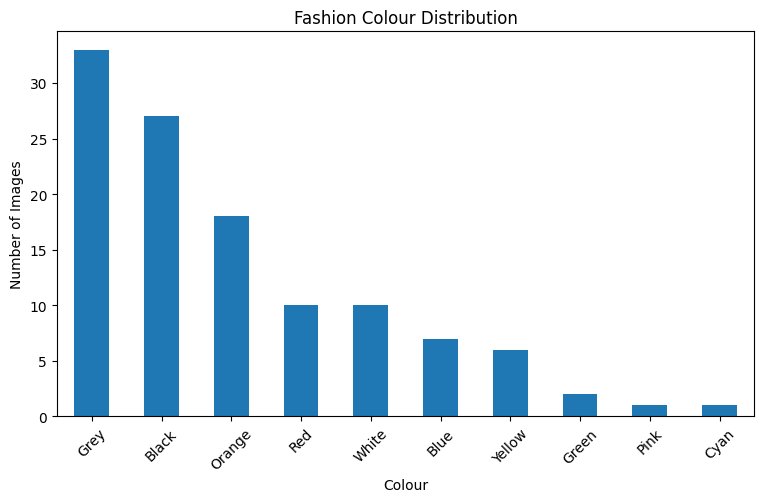

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

colour_counts.plot(kind='bar')

plt.title("Fashion Colour Distribution")
plt.xlabel("Colour")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.show()

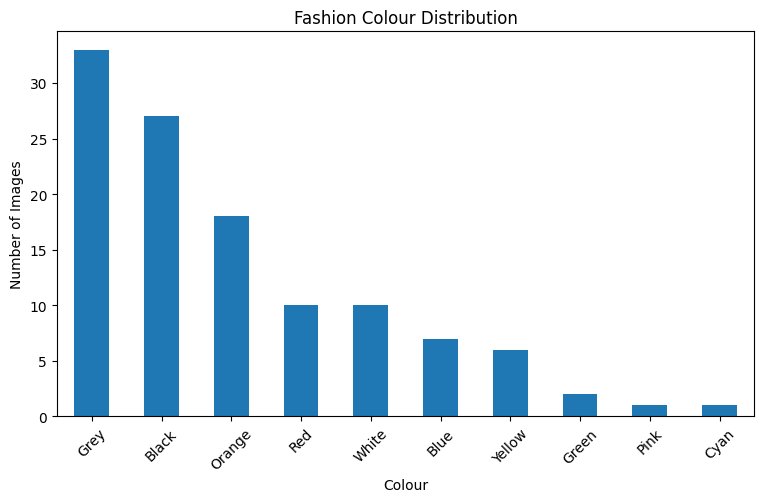

In [32]:
plt.figure(figsize=(9, 5))
colour_counts.plot(kind='bar')

plt.title("Fashion Colour Distribution")
plt.xlabel("Colour")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.savefig("fashion_colour_distribution.png", bbox_inches='tight')
plt.show()

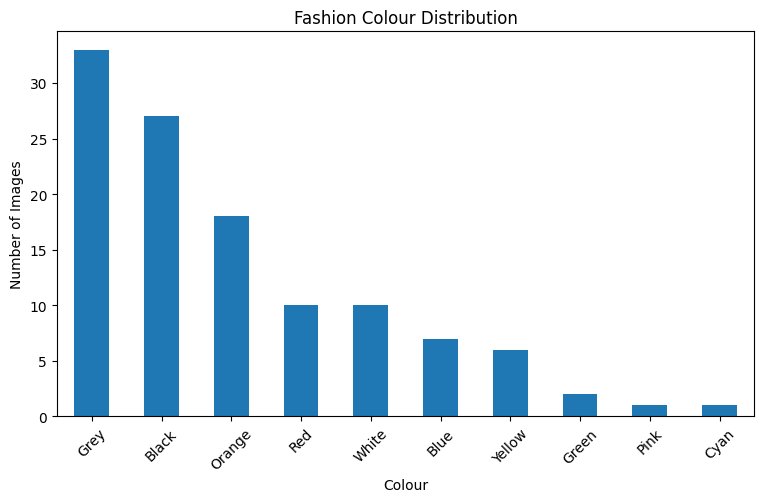

In [33]:
plt.figure(figsize=(9, 5))
colour_counts.plot(kind='bar')
plt.title("Fashion Colour Distribution")
plt.xlabel("Colour")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.savefig("fashion_colour_distribution.png", bbox_inches='tight')
plt.show()

In [34]:
from google.colab import files
files.download("fashion_colour_distribution.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
# Inspect the annotation structure of the first image
print(df.iloc[0]['objects'])

{'bbox_id': array([2583, 2584, 2585, 2586, 2587, 2588, 2589, 2590]), 'category': array([23, 23,  9, 28, 31, 31, 19, 34]), 'bbox': array([array([445., 837., 498., 944.]), array([475., 889., 531., 978.]),
       array([355., 245., 594., 667.]), array([379., 245., 502., 301.]),
       array([508., 273., 594., 541.]), array([355., 295., 389., 573.]),
       array([366., 397., 518., 449.]), array([421., 397., 441., 428.])],
      dtype=object), 'area': array([ 1475,  1703, 79872,  2153, 10313,  5710,  3712,   358])}


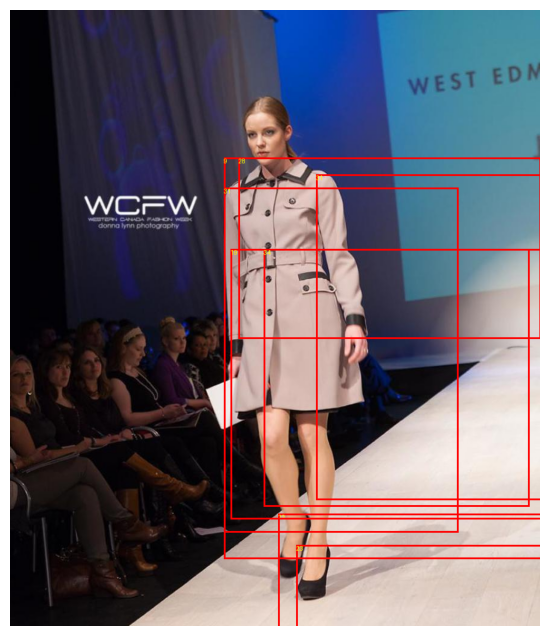

In [36]:
from PIL import Image, ImageDraw
from io import BytesIO
import matplotlib.pyplot as plt

row = df.iloc[0]

if isinstance(row['image'], dict):
    img = Image.open(BytesIO(row['image']['bytes'])).convert("RGB")
else:
    img = row['image'].convert("RGB")

objects = row['objects']

draw = ImageDraw.Draw(img)

for i, bbox in enumerate(objects['bbox']):
    x, y, w, h = bbox
    draw.rectangle(
        [x, y, x + w, y + h],
        outline="red",
        width=3
    )
    draw.text((x, y), str(objects['category'][i]), fill="yellow")

plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.axis("off")
plt.show()

In [37]:
row = df.iloc[0]
objects = row['objects']

print("Image dimensions:", row['width'], "x", row['height'])
print("\nObject annotations:")

for i in range(len(objects['bbox'])):
    print(
        "Object:", i,
        "| Category ID:", objects['category'][i],
        "| Bounding box:", objects['bbox'][i],
        "| Area:", objects['area'][i]
    )

Image dimensions: 880 x 1024

Object annotations:
Object: 0 | Category ID: 23 | Bounding box: [445. 837. 498. 944.] | Area: 1475
Object: 1 | Category ID: 23 | Bounding box: [475. 889. 531. 978.] | Area: 1703
Object: 2 | Category ID: 9 | Bounding box: [355. 245. 594. 667.] | Area: 79872
Object: 3 | Category ID: 28 | Bounding box: [379. 245. 502. 301.] | Area: 2153
Object: 4 | Category ID: 31 | Bounding box: [508. 273. 594. 541.] | Area: 10313
Object: 5 | Category ID: 31 | Bounding box: [355. 295. 389. 573.] | Area: 5710
Object: 6 | Category ID: 19 | Bounding box: [366. 397. 518. 449.] | Area: 3712
Object: 7 | Category ID: 34 | Bounding box: [421. 397. 441. 428.] | Area: 358


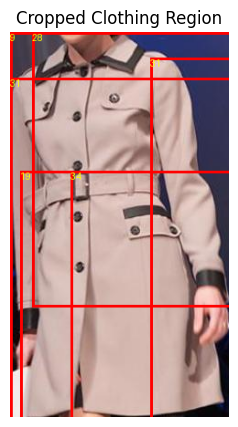

In [38]:
# Get the main garment bounding box (Object 2)
bbox = objects['bbox'][2]

x1, y1, x2, y2 = map(int, bbox)

# Crop the clothing region
clothing_crop = img.crop((x1, y1, x2, y2))

plt.figure(figsize=(5, 5))
plt.imshow(clothing_crop)
plt.axis("off")
plt.title("Cropped Clothing Region")
plt.show()

In [39]:
clothing_colors = []

for index, row in df.iterrows():

    # Load a fresh image (without the red annotation lines)
    if isinstance(row['image'], dict):
        image = Image.open(
            BytesIO(row['image']['bytes'])
        ).convert("RGB")
    else:
        image = row['image'].convert("RGB")

    objects = row['objects']

    if len(objects['bbox']) == 0:
        clothing_colors.append("Unknown")
        continue

    # Find the largest annotated object
    largest_index = objects['area'].argmax()

    # Get its bounding box
    x1, y1, x2, y2 = map(
        int, objects['bbox'][largest_index]
    )

    # Crop the garment region
    clothing_crop = image.crop((x1, y1, x2, y2))

    # Detect its dominant colour
    rgb = get_dominant_color(clothing_crop)
    colour = get_color_name(rgb)

    clothing_colors.append(colour)

results_df['clothing_colour'] = clothing_colors

print("Clothing colour detection completed!")
display(results_df.head(10))

Clothing colour detection completed!


,image_id,clothing_type,pattern,colour,clothing_colour
0,18111,A photograph of a jacket,Plain solid-colour clothing,Black,Red
1,19436,A photograph of trousers,Plain solid-colour clothing,Black,Orange
2,12153,A photograph of a jacket,Polka dot clothing,Black,Green
3,11931,A photograph of a dress,Floral patterned clothing,Orange,Orange
4,9390,A photograph of trousers,Plain solid-colour clothing,Red,Grey
5,10061,A photograph of trousers,Plain solid-colour clothing,Grey,Black
6,18165,A photograph of a skirt,Polka dot clothing,Grey,Black
7,15504,A photograph of a dress,Plain solid-colour clothing,Black,Black
8,10716,A photograph of a jacket,Floral patterned clothing,Blue,Blue
9,10696,A photograph of a dress,Plain solid-colour clothing,Red,Orange


In [40]:
clothing_colour_counts = results_df['clothing_colour'].value_counts()

print("CLOTHING COLOUR DISTRIBUTION")
print(clothing_colour_counts)

CLOTHING COLOUR DISTRIBUTION
clothing_colour
Black     23
Grey      23
Orange    20
Red       17
White     12
Blue      10
Green      3
Cyan       3
Pink       2
Yellow     2
Name: count, dtype: int64


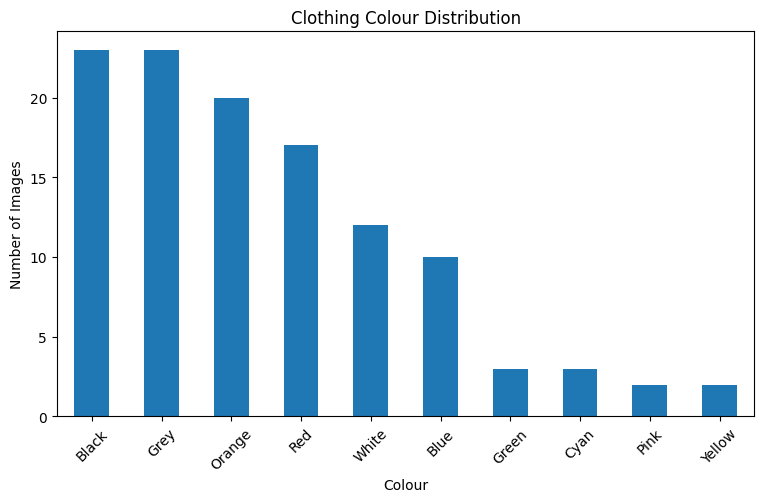

In [41]:
plt.figure(figsize=(9, 5))

clothing_colour_counts.plot(kind='bar')

plt.title("Clothing Colour Distribution")
plt.xlabel("Colour")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.savefig(
    "clothing_colour_distribution.png",
    bbox_inches="tight"
)

plt.show()

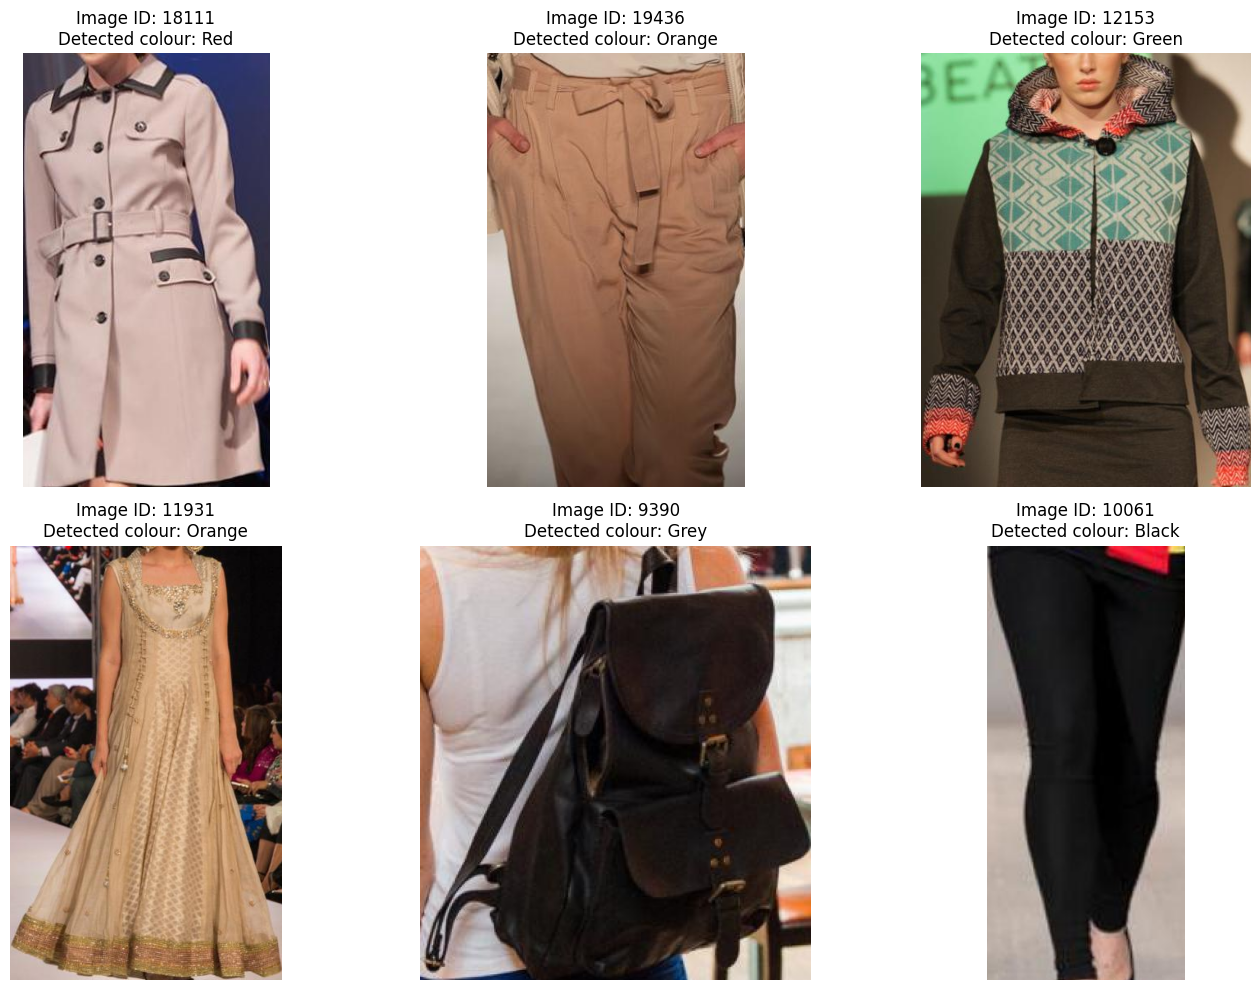

In [42]:
import matplotlib.pyplot as plt
from PIL import Image
from io import BytesIO

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for i, ax in enumerate(axes.flat):
    row = df.iloc[i]

    if isinstance(row['image'], dict):
        image = Image.open(
            BytesIO(row['image']['bytes'])
        ).convert("RGB")
    else:
        image = row['image'].convert("RGB")

    objects = row['objects']

    if len(objects['bbox']) == 0:
        ax.set_title("No annotations")
        ax.axis("off")
        continue

    largest_index = objects['area'].argmax()
    bbox = objects['bbox'][largest_index]

    x1, y1, x2, y2 = map(int, bbox)
    crop = image.crop((x1, y1, x2, y2))

    ax.imshow(crop)
    ax.set_title(
        f"Image ID: {row['image_id']}\n"
        f"Detected colour: {results_df.iloc[i]['clothing_colour']}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [43]:
from collections import Counter

category_counts = Counter()

for objects in df['objects']:
    category_counts.update(objects['category'].tolist())

print("CATEGORY ID DISTRIBUTION:")
for category_id, count in sorted(category_counts.items()):
    print(category_id, ":", count)

CATEGORY ID DISTRIBUTION:
0 : 9
1 : 53
3 : 1
4 : 17
5 : 4
6 : 25
7 : 10
8 : 18
9 : 7
10 : 52
11 : 2
12 : 1
13 : 11
14 : 7
15 : 15
18 : 9
19 : 16
21 : 14
22 : 5
23 : 143
24 : 21
25 : 4
26 : 1
27 : 4
28 : 19
29 : 10
30 : 2
31 : 130
32 : 54
33 : 97
34 : 8
35 : 24
36 : 8
37 : 8
38 : 1
40 : 3
41 : 1
42 : 6
43 : 5
44 : 3


In [44]:
clothing_category_ids = set(range(13))

clothing_colors = []

for index, row in df.iterrows():

    if isinstance(row['image'], dict):
        image = Image.open(
            BytesIO(row['image']['bytes'])
        ).convert("RGB")
    else:
        image = row['image'].convert("RGB")

    objects = row['objects']

    # Find annotations belonging to main clothing categories
    valid_indices = [
        i for i, category_id in enumerate(objects['category'])
        if category_id in clothing_category_ids
    ]

    if not valid_indices:
        clothing_colors.append("Unknown")
        continue

    # Select the largest clothing annotation
    largest_index = max(
        valid_indices,
        key=lambda i: objects['area'][i]
    )

    x1, y1, x2, y2 = map(
        int, objects['bbox'][largest_index]
    )

    clothing_crop = image.crop((x1, y1, x2, y2))

    rgb = get_dominant_color(clothing_crop)
    colour = get_color_name(rgb)

    clothing_colors.append(colour)

results_df['clothing_colour'] = clothing_colors

print("Updated clothing colour detection completed!")
display(results_df.head(10))

Updated clothing colour detection completed!


,image_id,clothing_type,pattern,colour,clothing_colour
0,18111,A photograph of a jacket,Plain solid-colour clothing,Black,Red
1,19436,A photograph of trousers,Plain solid-colour clothing,Black,Orange
2,12153,A photograph of a jacket,Polka dot clothing,Black,Green
3,11931,A photograph of a dress,Floral patterned clothing,Orange,Orange
4,9390,A photograph of trousers,Plain solid-colour clothing,Red,Blue
5,10061,A photograph of trousers,Plain solid-colour clothing,Grey,Black
6,18165,A photograph of a skirt,Polka dot clothing,Grey,Black
7,15504,A photograph of a dress,Plain solid-colour clothing,Black,Black
8,10716,A photograph of a jacket,Floral patterned clothing,Blue,Blue
9,10696,A photograph of a dress,Plain solid-colour clothing,Red,Orange


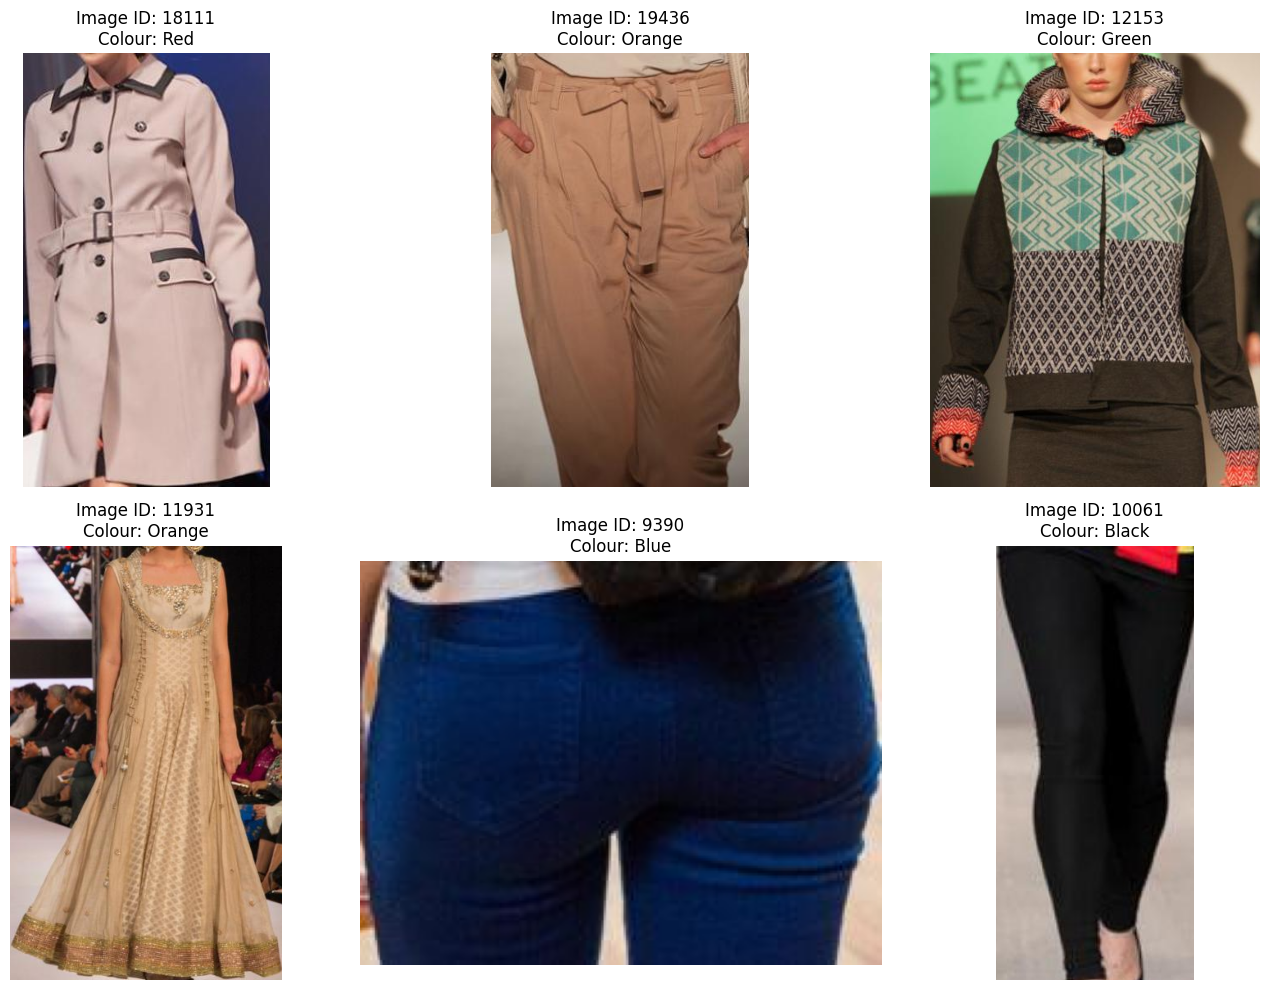

In [45]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for i, ax in enumerate(axes.flat):
    row = df.iloc[i]
    objects = row['objects']

    if isinstance(row['image'], dict):
        image = Image.open(
            BytesIO(row['image']['bytes'])
        ).convert("RGB")
    else:
        image = row['image'].convert("RGB")

    valid_indices = [
        j for j, cat in enumerate(objects['category'])
        if cat in clothing_category_ids
    ]

    if not valid_indices:
        ax.set_title("No clothing detected")
        ax.axis("off")
        continue

    largest_index = max(
        valid_indices,
        key=lambda j: objects['area'][j]
    )

    x1, y1, x2, y2 = map(
        int, objects['bbox'][largest_index]
    )

    crop = image.crop((x1, y1, x2, y2))

    ax.imshow(crop)
    ax.set_title(
        f"Image ID: {row['image_id']}\n"
        f"Colour: {results_df.iloc[i]['clothing_colour']}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [46]:
print("Unknown colours:",
      (results_df['clothing_colour'] == 'Unknown').sum())

Unknown colours: 0


In [47]:
# Save the final results CSV
results_df.to_csv(
    "fashionpedia_final_results.csv",
    index=False
)

print("Final dataset saved!")
print("Total images:", len(results_df))
print("Columns:", results_df.columns.tolist())

Final dataset saved!
Total images: 115
Columns: ['image_id', 'clothing_type', 'pattern', 'colour', 'clothing_colour']


In [48]:
from google.colab import files

files.download("fashionpedia_final_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

FINAL CLOTHING COLOUR DISTRIBUTION
clothing_colour
Grey      23
Black     23
Orange    20
Red       17
White     11
Blue      11
Cyan       3
Green      3
Pink       2
Yellow     2
Name: count, dtype: int64


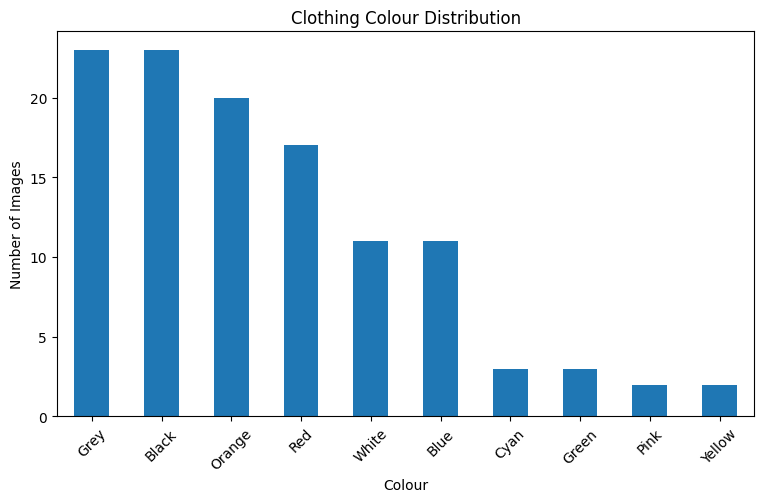

In [49]:
# Count clothing colours
clothing_colour_counts = results_df['clothing_colour'].value_counts()

print("FINAL CLOTHING COLOUR DISTRIBUTION")
print(clothing_colour_counts)

# Generate graph
plt.figure(figsize=(9, 5))

clothing_colour_counts.plot(kind='bar')

plt.title("Clothing Colour Distribution")
plt.xlabel("Colour")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.savefig(
    "final_clothing_colour_distribution.png",
    bbox_inches="tight"
)

plt.show()

In [50]:
files.download("final_clothing_colour_distribution.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [51]:
# Compare both colour detection methods

comparison = pd.DataFrame({
    "Whole Image Detection": results_df['colour'].value_counts(),
    "Clothing Region Detection": results_df['clothing_colour'].value_counts()
}).fillna(0)

print("COLOUR DETECTION COMPARISON")
display(comparison)

COLOUR DETECTION COMPARISON


,Whole Image Detection,Clothing Region Detection
Black,27,23
Blue,7,11
Cyan,1,3
Green,2,3
Grey,33,23
Orange,18,20
Pink,1,2
Red,10,17
White,10,11
Yellow,6,2


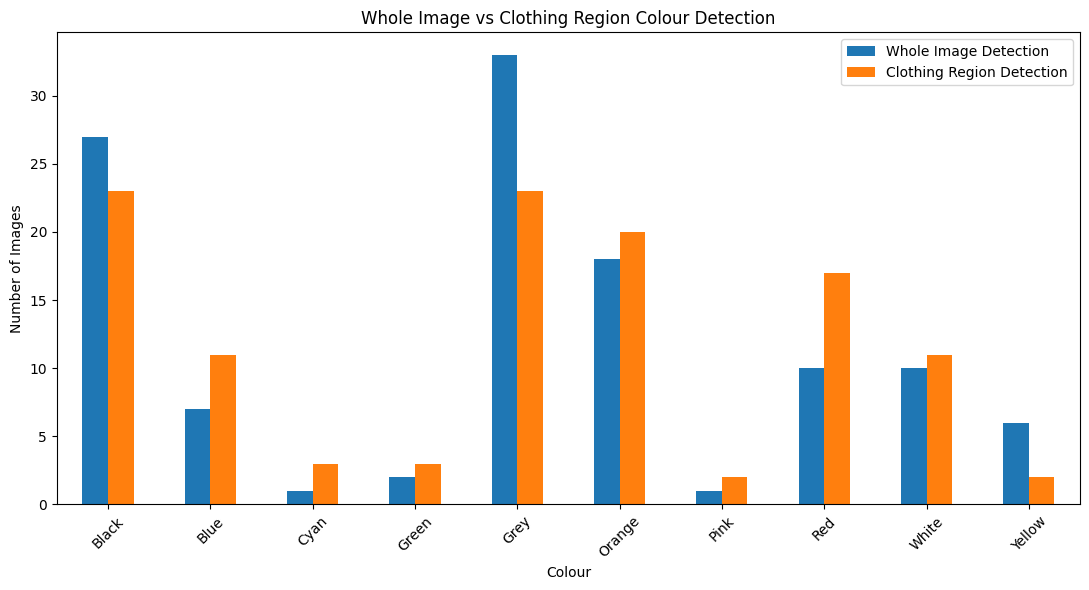

In [52]:
comparison.plot(
    kind='bar',
    figsize=(11, 6)
)

plt.title("Whole Image vs Clothing Region Colour Detection")
plt.xlabel("Colour")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.savefig(
    "colour_detection_comparison.png",
    bbox_inches="tight"
)

plt.show()

In [53]:
files.download("colour_detection_comparison.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [54]:
import os

print("FILES CREATED IN COLAB:\n")

for file in os.listdir("/content"):
    if file.endswith((".csv", ".png", ".ipynb")):
        print(file)

FILES CREATED IN COLAB:

fashion_colour_distribution.png
fashionpedia_final_results.csv
colour_detection_comparison.png
fashionpedia_clip_results.csv
final_clothing_colour_distribution.png
clothing_colour_distribution.png
